Generating and preprocessing the Online Retail customer dataset...
Training samples: 1600
Testing samples: 400

--- Model Performance ---
Decision Tree Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       300
           1       1.00      1.00      1.00       100

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


--- Feature Importance Analysis ---
     Feature  Importance
1  Frequency    0.596761
2   Monetary    0.403239
0    Recency    0.000000


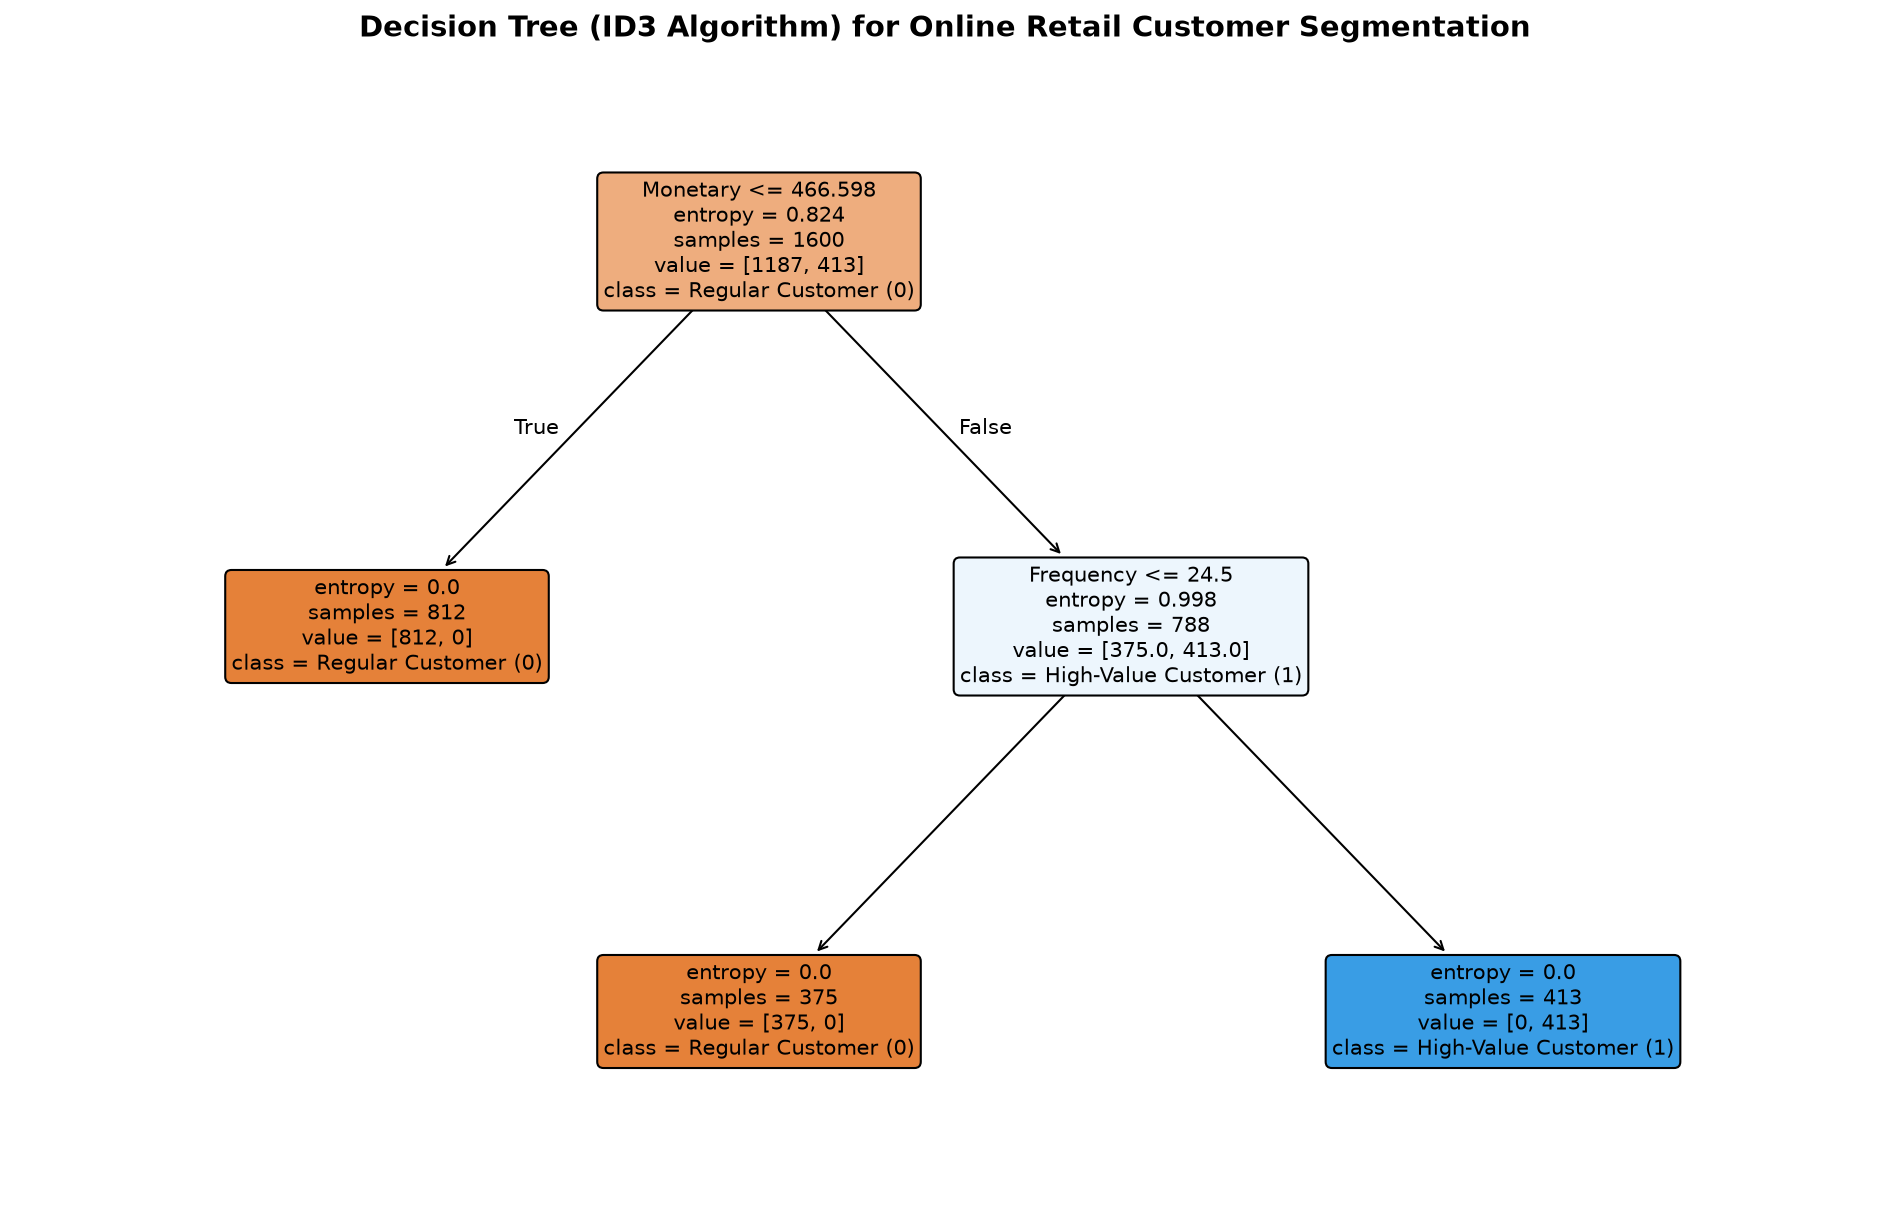

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report


print("Generating and preprocessing the Online Retail customer dataset...")


np.random.seed(42)
n_samples = 2000

data = {
    'Recency': np.random.randint(1, 365, size=n_samples),       # Days since last purchase
    'Frequency': np.random.randint(1, 50, size=n_samples),      # Total number of transactions
    'Monetary': np.random.exponential(600, size=n_samples) + 50 # Total money spent
}

df = pd.DataFrame(data)


df = df.dropna()


monetary_median = df['Monetary'].median()
frequency_median = df['Frequency'].median()

df['Customer_Segment'] = np.where(
    (df['Monetary'] >= monetary_median) & (df['Frequency'] >= frequency_median), 
    1, 0
)


X = df[['Recency', 'Frequency', 'Monetary']]
y = df['Customer_Segment']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")


id3_classifier = DecisionTreeClassifier(
    criterion='entropy', 
    max_depth=4, 
    random_state=42
)
id3_classifier.fit(X_train, y_train)


y_pred = id3_classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("\n--- Model Performance ---")
print(f"Decision Tree Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ==========================================
# 3. Analyze Feature Importance
# ==========================================
importances = id3_classifier.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\n--- Feature Importance Analysis ---")
print(feature_importance_df)

# ==========================================
# 4. Visualize the Decision Tree
# ==========================================
plt.figure(figsize=(16, 10), dpi=150)
plot_tree(
    id3_classifier, 
    feature_names=X.columns, 
    class_names=['Regular Customer (0)', 'High-Value Customer (1)'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (ID3 Algorithm) for Online Retail Customer Segmentation", fontsize=14, fontweight='bold')
plt.show()